# Pronosticar después de una estación incompleta

**Pregunta:** Al mover el origen cinco observaciones hacia atrás, ¿HoltWinters continúa la fase estacional correcta y cómo se comparan sus errores por paso con una estación repetida?

## Objetivos

Investigaremos un riesgo concreto de implementación sin asumir que el nombre conocido de un método garantiza un pronóstico correcto. Acortaremos una historia comprometida, construiremos el objetivo correspondiente con las observaciones posteriores al nuevo origen y ejecutaremos HoltWinters aditivo del producto. Compararemos la trayectoria con métodos más simples e inspeccionaremos errores agregados y por paso. El experimento cambia deliberadamente el corte temporal y mantiene fija la secuencia observada subyacente.

Un modelo estacional almacena componentes indexados según su posición dentro del ciclo. Si la historia termina a mitad de ese ciclo, el pronóstico debe continuar desde esa posición. Reiniciar el componente en la primera casilla puede generar una oscilación plausible, pero desfasada. El defecto pasa inadvertido cuando todas las historias de demostración contienen ciclos completos. Por eso retiramos una cantidad fija y declarada de observaciones antes del ajuste, en lugar de escogerla después de observar los resultados.

## Preparación

Utilice el entorno aislado de cuadernos con estas dependencias directas exactas. El código importa las funciones del producto y no define una segunda implementación cuyo comportamiento pueda diferir del utilizado en la aplicación.

```text
pip install numpy==2.4.6
pip install scipy==1.15.3
pip install matplotlib==3.10.8
pip install statsforecast==2.0.3
pip install lightgbm==4.6.0
pip install mlforecast==1.0.31
pip install nbformat==5.11.1
pip install nbclient==0.11.0
pip install ipykernel==7.4.0
pip install stumpy==1.14.1
pip install antropy==0.2.2
pip install nolds==0.6.3
pip install pycatch22==0.4.5
pip install scikit-learn==1.9.1
pip install preqts==0.3.0
```


In [1]:
# Configure a portable lesson session; no data are downloaded.
from pathlib import Path
import sys
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in Path.cwd().parents if (p / "VERSION").is_file() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from chronoscopelab.model.forecasters import seasonal_naive, ses, holt, holt_winters, theta
from chronoscopelab.model.forecasters import gaussian_quantiles
from chronoscopelab.model.context_memory import fit_context_memory
from chronoscopelab.reevaluation import metrics
from chronoscopelab.engines.statsforecast_engine import StatsforecastForecaster
from chronoscopelab.engines.lightgbm_engine import LightGBMForecaster
plt.rcParams.update({"figure.figsize": (8, 3), "figure.dpi": 95, "font.size": 10})
plt.rcParams["svg.hashsalt"] = "chronoscope-lessons"
import importlib.metadata
packages = ("numpy", "scipy", "matplotlib", "statsforecast", "lightgbm", "mlforecast",
            "nbformat", "nbclient", "ipykernel")
for package in packages:
    print(package, importlib.metadata.version(package))


numpy 2.4.6
scipy 1.15.3
matplotlib 3.10.8
statsforecast 2.0.3
lightgbm 4.6.0
mlforecast 1.0.31
nbformat 5.11.1
nbclient 0.11.0
ipykernel 7.4.0


## Datos

La traza generada con tendencia y estacionalidad contiene un prefijo histórico y un bloque final reservado. Para el origen anterior, las cinco observaciones históricas finales pasan a ser los primeros objetivos futuros. Los objetivos restantes provienen del bloque reservado original. Esta concatenación conserva el orden cronológico. Ninguna observación recién reservada entra al ajuste. Las medidas del origen anterior no deben compararse como si utilizaran el objetivo original: cambiaron la información disponible, el bloque futuro y la pregunta experimental.


In [2]:
# The committed trace separates available history from the unseen final block.
trace = json.loads((root / "data/derived/TRND_seasonal/trace.json").read_text())
history = np.array(trace["history"], dtype=float)
actual = np.array(trace["actual"], dtype=float)
m, h = trace["seasonality"], trace["horizon"]
comparison = json.loads((root / "data/derived/reevaluation.json").read_text())
print("History:", len(history), "Season:", m, "Holdout:", h)


History: 168 Season: 12 Holdout: 12


## Método

El primer ajuste utiliza el prefijo acortado. El segundo emplea la historia original completa y se conserva solamente para distinguir ambos orígenes. En HoltWinters aditivo, nivel, tendencia y componentes estacionales se actualizan conjuntamente mediante rejillas finitas de parámetros. El pronóstico debe elegir la casilla correspondiente a la longitud completa del prefijo más el paso solicitado. El resto impreso indica si la historia acortada termina en un límite de ciclo. Ese valor verifica la condición experimental y no mide la precisión del método.


In [3]:
# Remove five known observations to create an incomplete terminal season.
short = history[:-5]
short_actual = np.concatenate((history[-5:], actual))[:h]
hw_point, hw_sigma = holt_winters(short, m, h)
full_hw, full_sigma = holt_winters(history, m, h)
print("Removed observations:", len(history) - len(short))
print("Partial history remainder:", len(short) % m)
print("Forecast horizon:", h)


Removed observations: 5
Partial history remainder: 7
Forecast horizon: 12


SeasonalNaive proporciona una referencia alineada porque copia el último ciclo observado respecto del nuevo origen. Theta aporta otra comparación con deriva, sin la misma estructura estacional ajustada automáticamente. Ambos deben volver a ajustarse sobre la historia corta. Mantener una predicción entrenada con el prefijo original daría a ese competidor observaciones que el método del origen anterior no pudo conocer. Esta es una fuga temporal que no se evita simplemente compartiendo el bloque objetivo entre los modelos.


In [4]:
# Refit the seasonal reference and Theta at the earlier origin as well.
short_naive, short_sigma = seasonal_naive(short, m, h)
short_theta, short_theta_sigma = theta(short, m, h)
short_q = gaussian_quantiles(hw_point, hw_sigma, (0.1, 0.5, 0.9))
print("HoltWinters first prediction:", round(float(hw_point[0]), 4))


HoltWinters first prediction: 109.587


La ecuación Theta local corregida sigue siendo un contraste útil aunque su medida no sea el resultado principal. La corrección de historia finita depende de la cantidad de observaciones disponibles: mover el origen también modifica esa contribución. Una revisión limitada a las formas del pronóstico puede ignorar estas dependencias. Ejecutamos nuevamente la implementación con el prefijo original para dejar explícita su información, manteniendo las medidas del origen anterior vinculadas exclusivamente a sus predicciones correspondientes.


In [5]:
# Fit the finite-history Theta implementation on the same prefix.
theta_point, theta_sigma = theta(history, m, h)
theta_q = gaussian_quantiles(theta_point, theta_sigma, (0.1, 0.5, 0.9))
print("Theta first prediction:", round(float(theta_point[0]), 4))


Theta first prediction: 113.1748


La evaluación utiliza el prefijo acortado para calcular la escala histórica estacional y el objetivo recién ensamblado para calcular errores futuros. La cobertura es la proporción de objetivos contenidos entre los cuantiles gaussianos inferior y superior. Es una fracción muestral de un bloque y no una garantía probabilística para la observación siguiente. Debe leerse junto con la amplitud: intervalos muy extensos pueden cubrir más objetivos sin orientar una decisión útil. No optimizamos sus parámetros contra los datos reservados.


In [6]:
# The earlier-origin target is different, so its scores form a separate experiment.
short_score = metrics(short, short_actual, hw_point, short_q[:, 0], short_q[:, 2], m)
print("Earlier-origin MASE:", round(short_score["mase"], 4))
print("Earlier-origin coverage:", round(short_score["coverage"], 4))


Earlier-origin MASE: 0.4948
Earlier-origin coverage: 1.0


En la primera figura, compare las posiciones de los máximos predichos y observados. Una implementación correcta todavía puede producir errores grandes porque la tendencia o la amplitud estimada resultan imperfectas. A la inversa, un error agregado bajo en una serie casi plana ofrecería poca evidencia sobre la indexación estacional. Este caso tiene estructura visible para inspeccionar la fase. Además, las pruebas independientes del repositorio ejercitan historias cuyas longitudes no son divisibles por el período, evitando depender únicamente de esta inspección visual.


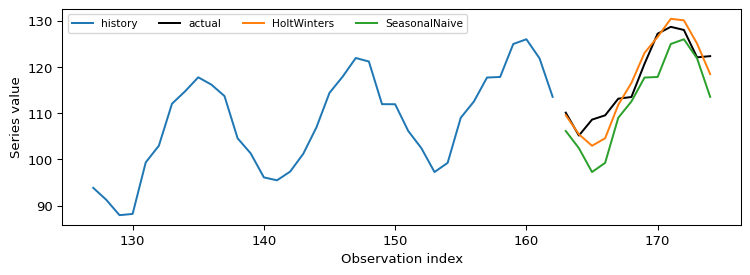

In [7]:
# Display phase alignment around the deliberately shifted origin.
fig, ax = plt.subplots()
x = np.arange(len(short), len(short) + h)
ax.plot(np.arange(len(short))[-36:], short[-36:], label="history")
ax.plot(x, short_actual, color="black", label="actual")
ax.plot(x, hw_point, label="HoltWinters")
ax.plot(x, short_naive, label="SeasonalNaive")
ax.set(xlabel="Observation index", ylabel="Series value")
ax.legend(ncol=4, fontsize=8)
fig.tight_layout()
plt.show()


Las trayectorias separan alineación de precisión. Continuar las casillas correctas es necesario para el algoritmo declarado, pero no garantiza que su componente estacional siga siendo apropiado en otro régimen. Revise conjuntamente el origen y la oscilación antes de atribuir cualquier discrepancia a la fase. Un cambio de nivel o una deriva imperfecta puede desplazar toda la predicción y mantener intactas sus posiciones estacionales. Esa diferencia motiva inspeccionar los errores individuales de la figura siguiente.

Los errores absolutos por paso conservan las unidades e identifican qué observaciones dominan el promedio. Cada punto corresponde a un error de un origen, no a una estimación promediada sobre numerosos orígenes. Por ello, un máximo puede reflejar un objetivo inusual y no una debilidad general del horizonte. Mostramos la referencia estacional sobre los mismos ejes para observar la mejora relativa directamente. No adjuntamos intervalos de confianza ni pruebas de significancia a esta pequeña comparación determinista.


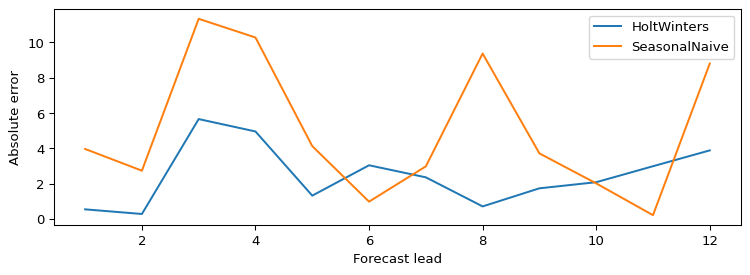

Seasonal reference MASE: 1.0136


In [8]:
# Inspect errors by lead; an average can hide phase-specific failures.
short_naive_q = gaussian_quantiles(short_naive, short_sigma, (0.1, 0.5, 0.9))
short_naive_score = metrics(short, short_actual, short_naive, short_naive_q[:, 0], short_naive_q[:, 2], m)
fig, ax = plt.subplots()
ax.plot(np.arange(1, h + 1), np.abs(short_actual - hw_point), label="HoltWinters")
ax.plot(np.arange(1, h + 1), np.abs(short_actual - short_naive), label="SeasonalNaive")
ax.set(xlabel="Forecast lead", ylabel="Absolute error")
ax.legend()
fig.tight_layout()
plt.show()
print("Seasonal reference MASE:", round(short_naive_score["mase"], 4))


El gráfico muestra si los métodos fallan en las mismas posiciones o intercambian errores a lo largo del bloque. Sus curvas pueden cruzarse: reducir el promedio no implica mejorar cada paso. Esto importa cuando la planificación valora más el servicio inmediato que un pronóstico distante. Esos costos deben declararse antes de escoger una medida ponderada. Aquí asignamos el mismo peso a cada paso y conservamos el MASE de la referencia calculado de forma independiente.

## Resultados

**Respuesta:** HoltWinters obtiene MASE 0,4948 en el origen anterior, frente a 1,0136 de SeasonalNaive. Retirar cinco observaciones produce una estación incompleta que la implementación corregida continúa desde su posición terminal real. Las trayectorias y medidas impresas cuantifican este caso. La curva compara cada paso con SeasonalNaive sobre el mismo objetivo nuevo; no permite ordenar estos métodos mediante medidas del origen original posterior.

Corrección de implementación y calidad empírica son conclusiones separadas. Una prueba de estación incompleta puede refutar una regla de indexación sin afirmar superioridad poblacional. Un error observado puede refutar una expectativa de precisión sin demostrar que la indexación esté equivocada. Conserve ambos tipos de evidencia al diagnosticar un pronóstico y mantenga los resultados desfavorables, en vez de cambiar el origen hasta que gane el método preferido.

## Resumen

Registre la información exacta cada vez que mueva el corte temporal. Construya su objetivo futuro en orden cronológico, vuelva a ajustar todos los competidores y recalcule la escala histórica con ese prefijo. Use historias adversariales con estaciones incompletas para comprobar un algoritmo estacional. Después examine medidas del bloque completo y errores individuales, recordando que un origen no proporciona una estimación poblacional ni una aceptación de despliegue.


### Sensibilidad a la posición dentro de un día

Numera las observaciones del prefijo desde cero. Si su longitud es $n$, la
siguiente fase estacional corresponde a $n\bmod m$. El ajuste aditivo de
HoltWinters conserva un nivel $\ell$ en las unidades de la serie y una
tendencia $b$ en esas unidades por paso, junto con $m$ efectos estacionales
$s$ en las unidades originales. Para un paso $j$ contado desde uno, el
pronóstico implementado es

$$
\widehat y_{n+j-1} = \ell + jb + s_{(n+j-1)\bmod m}.
$$

Con $m=12$, un prefijo de longitud 125 avanza a la fase 5. Empezar el
pronóstico en la fase cero reutilizaría la posición estacional de la primera
observación aunque ya se hayan consumido cinco posiciones de ese ciclo.
Al mover el corte hay que ajustar nuevamente el método porque también cambian
el nivel y la tendencia estimados. La implementación prueba cuatro coeficientes
de nivel, dos de tendencia y tres de estacionalidad. Selecciona la combinación
que minimiza la suma de residuos cuadrados a un paso tras el primer ciclo.
Si el prefijo contiene menos de dos ciclos completos, la función devuelve
la proyección de Holt porque la inicialización estacional requiere más datos.

El control generado anterior permite aislar la fase con un período conocido.
El siguiente cálculo usa el extracto eléctrico MT_010 publicado por Trindade
en UCI (CC BY 4.0, [DOI 10.24432/C58C86](https://doi.org/10.24432/C58C86)).
Cada fila con etiqueta horaria suma cuatro lecturas consecutivas de potencia
en kW. El valor agregado no se ha convertido a energía. La primera etiqueta
es 00:15 y las sucesivas avanzan una hora. El extracto tiene 480 filas. La
referencia diaria usa $m=24$ y la semanal $m=168$. Comparamos ambos pronósticos
estacionales ingenuos y HoltWinters diario en cortes entre 312 y 368,
separados por siete observaciones para visitar distintas fases. En cada corte
los tres métodos predicen las mismas 24 observaciones reservadas. La escala
del error emplea el retardo diario para los tres, de modo que la referencia
semanal no obtiene un denominador diferente.

$$
s_{24}(y_{0:n})=\frac{1}{n-24}\sum_{i=24}^{n-1}|y_i-y_{i-24}|,
\qquad
\operatorname{MASE}_{24}=\frac{\sum_{j=1}^{24}|a_j-\widehat y_{n+j-1}|}{24s_{24}(y_{0:n})}.
$$

La referencia diaria debe repetir exactamente las 24 observaciones que
preceden al corte. La celda calcula la diferencia máxima frente al índice directo, que debe ser cero.


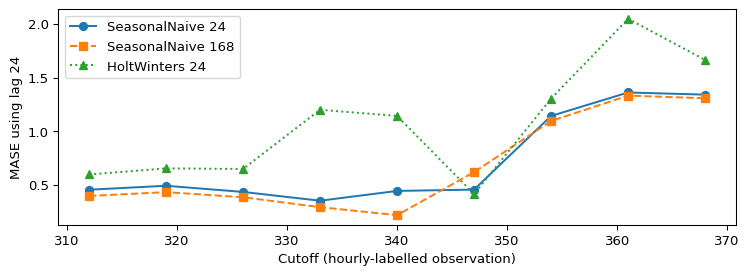

Largest difference from direct seasonal indexing: 0.0
Cutoff  /  next daily phase  /  daily MASE  /  weekly MASE  /  smoothed MASE
   312         0     0.4543     0.3963     0.5965
   319         7     0.4912     0.4319     0.6531
   326        14     0.4338     0.3839     0.6479
   333        21     0.3518     0.2916     1.1994
   340         4     0.4431     0.2171     1.1424
   347        11     0.4554     0.6186     0.4142
   354        18     1.1421     1.0952     1.3039
   361         1     1.3610     1.3317     2.0477
   368         8     1.3407     1.3069     1.6645


In [9]:
# Compare daily phase and a weekly seasonal reference on the same reserved hours.
electricity = np.loadtxt(root / "data/examples/electricity_sample.csv", delimiter=",", skiprows=1, usecols=2)
origins = np.arange(312, 369, 7)
scores, reference_errors = [], []
for origin in origins:
    prefix = electricity[:origin]
    targets = electricity[origin:origin + 24]
    daily, _ = seasonal_naive(prefix, 24, 24)
    weekly, _ = seasonal_naive(prefix, 168, 24)
    smooth, _ = holt_winters(prefix, 24, 24)
    reference_errors.append(np.max(np.abs(daily - prefix[origin - 24:origin])))
    scale = np.mean(np.abs(prefix[24:] - prefix[:-24]))
    scores.append([np.mean(np.abs(targets - path)) / scale for path in (daily, weekly, smooth)])
scores = np.asarray(scores)
fig, ax = plt.subplots()
for j, (name, style) in enumerate((("SeasonalNaive 24", "o-"), ("SeasonalNaive 168", "s--"), ("HoltWinters 24", "^:"))):
    ax.plot(origins, scores[:, j], style, label=name)
ax.set(xlabel="Cutoff (hourly-labelled observation)", ylabel="MASE using lag 24")
ax.legend()
fig.tight_layout()
plt.show()
print("Largest difference from direct seasonal indexing:", max(reference_errors))
print("Cutoff  /  next daily phase  /  daily MASE  /  weekly MASE  /  smoothed MASE")
for origin, row in zip(origins, scores, strict=True):
    print(f"{origin:6d} {origin % 24:9d} " + " ".join(f"{value:10.4f}" for value in row))


La figura compara métodos para cada corte particular. Cuando las curvas se
cruzan, el orden local cambia. Lee en la tabla la fase junto al índice:
una fase se puede repetir con distinta historia de días de la semana, por
lo que la fase no explica por sí sola la diferencia de puntuación. Los
bloques objetivo se solapan: los cortes distan siete observaciones y cada
bloque abarca 24. Los nueve puntos no son nueve réplicas independientes.
La referencia semanal reutiliza un día específico de la semana anterior.
Un error alto en un corte no descarta un patrón semanal en toda la serie.

### Úsalo con tus propios datos

Prepara una sola serie finita con marcas temporales ordenadas y regulares.
Identifica qué lecturas estaban disponibles antes de emitir el pronóstico.
Para una serie horaria con un ciclo diario plausible usa 24 como período
inicial, y comprueba la frecuencia antes de usar 168. Una hora ausente y una
lectura cero tienen significados distintos. No comprimas el eje temporal si
faltan filas. Separa el bloque contiguo que usarás para medir error antes
de llamar a `holt_winters(prefix, m, horizon)`. La salida contiene la
trayectoria solicitada y una dispersión de residuos en las unidades de la
entrada. Comprueba la longitud del vector y contrasta la fase con la
referencia estacional indexada de forma independiente. Estima la escala
solo con el prefijo. Una serie constante o exactamente periódica puede dar
una escala nula y dejar el error escalado sin definir. Conserva el error
absoluto para documentar ese caso. Si construyes intervalos gaussianos con
la dispersión, lee la cobertura observada junto con la anchura. El método
puede acertar la fase y errar el nivel o la amplitud del siguiente ciclo.

## Referencias

- Continuación estacional: https://otexts.com/fpp3/holt-winters.html
- Corrección Theta: https://robjhyndman.com/papers/Theta.pdf
- Escalamiento: https://doi.org/10.1016/j.ijforecast.2006.03.001
- Combinaciones por características: https://doi.org/10.1016/j.ijforecast.2019.02.011
- Ensambles dinámicos: https://doi.org/10.1007/s10994-018-05774-y
- A. Trindade, ElectricityLoadDiagrams20112014, UCI. [Datos](https://doi.org/10.24432/C58C86).
